# MECHA in metafspm, 6: the solutes' storage and decay

MechaSolutes' balance per liquid node (doc/equations.rst, Solutes):

$$C V \frac{c - c^\text{prev}}{\Delta t} + \sum J + k_\text{decay} V c + O\,c + \ldots = S + I\,c_b$$

Three of its terms come from MECHA's `develop` branch (its tutorial 04, `example/legacy/tutorial_04_capacitance_reaction.ipynb`):

- the **storage fraction** :math:`C` (`storage_fraction_wall`, `storage_fraction_cell`; the reactions' `C_wall`,
  `C_cell`): the part of a node's volume that stores the solute, 1 by default;
- the **first-order loss** :math:`k_\text{decay}` (`k_decay`, d⁻¹; their `k_deg`): consumption or degradation on
  every liquid node, 0 by default;
- the **liquid boundary** (`solute_boundary_advection`, `c_boundary`; their `conserve_boundary`): the water a node
  exchanges with the outside of its section's liquid network carries the solute out, or brings `c_boundary` in.
  Water leaving as vapour leaves its solute behind.

All three are compared with the legacy (`test/comparison/test_solutes.py`, `test_solute_boundary_exchange.py`).
**Run time:** about 15 seconds.

> **Developer tutorial 6** of ten:
> | | notebook | what it covers |
> |---|---|---|
> | 0 | `00_overview.ipynb` | the package's modules, the original MECHA and its reactions branch, how the port is validated, the docs |
> | 1 | `01_granap_mecha.ipynb` | GRANAP's anatomies and MECHA's hydraulics coupled in a plant model; MECHA's inputs by role; scenarios; the barriers |
> | 2 | `02_soil_gradient.ipynb` | the plant problem with a soil drier on one side of a root section; a root partly out of contact, by position or by cells |
> | 3 | `03_needle_solutes.ipynb` | a pine needle of three sections, its transpiration, MechaSolutes over a day |
> | 4 | `04_full_plant.ipynb` | a whole seedling in its soil, run to the fixed point |
> | 5 | `05_extend_the_component.ipynb` | add a variable and a process to the component, run and test it |
> | 6 | `06_solute_storage_and_decay.ipynb` | the solutes' storage fractions, their first-order loss and the liquid boundary |
> | 7 | `07_section_options.ipynb` | the section's hydraulic options: the barrier codes 0-11, φ-thickenings, aquaporins, plasmodesmata rules, walls, xylem pieces, tracheids, measured axial conductances |
> | 8 | `08_standard_problem.ipynb` | the standard problem's boundaries (soil sides, xylem and phloem pressures or flows, the elongation zone), the osmotic scenarios, the flows by layer |
> | 9 | `09_solute_options.ipynb` | the solutes' pathways, schemes and time steps, held concentrations and steady states, the coupled water and sugar |
>
> New to MECHA? Start with the user tutorials (`../user/01_first_run.ipynb`): they solve a root section and explain
> its results without the framework's details.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from openalea.metafspm.coupling.composite_wrapper import CompositeModel
from openalea.metafspm.coupling.translator import Translator
from openalea.metafspm.scene.scene import Scene

from openalea.granap.metafspm.architectures import RootAxis
from openalea.granap.metafspm.component import GranapAnatomy, junction_rules
from openalea.mecha.component import MechaHydraulics
from openalea.mecha.solutes import MechaSolutes


class RootSugars(CompositeModel):
    """One root segment: GRANAP's anatomy, MECHA's hydraulics, MECHA's solutes."""
    initiators = (RootAxis, GranapAnatomy)
    from_scale, nodes, wiring = "SubOrgan", "Compartment", junction_rules

    def __init__(self, data_structure, time_step):
        self.anatomy = GranapAnatomy(data_structure=data_structure, time_step=time_step)
        self.hydraulics = MechaHydraulics(data_structure=data_structure, time_step=time_step)
        self.solutes = MechaSolutes(data_structure=data_structure, time_step=time_step)
        self.declare_data_and_couple_components(translator_path=Translator(),
                                                components=(self.anatomy, self.hydraulics, self.solutes))

    def run(self):
        self.anatomy()
        self.hydraulics()
        self.solutes()

## 1. A day of sucrose in a root section

Each cortex cell produces 10⁻¹² mol d⁻¹ of sucrose (`sucrose_source`, as a carbon model would give it); the phloem
and the xylem are the sinks. One step per hour for a day, from no sucrose; the free nodes' sucrose content
:math:`\sum C V c` is recorded.

defaults            3.957571e-11
walls store 20 %    3.823005e-11
decay 2 d⁻¹         3.455084e-11
no boundary         3.957571e-11
Name: after 24 h (mol), dtype: float64

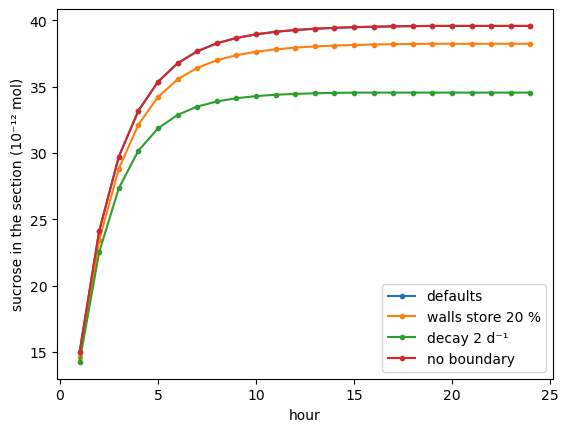

In [2]:
SOURCE = 1e-12                                             # mol d-1 per cortex cell


def day(**parameters):
    """24 hourly steps with MechaSolutes' *parameters*; the free nodes' sucrose content after each (mol)."""
    scenario = {"collar_condition": 1., "collar_psi": -5000., "standard_solve": 0., **parameters}
    scene = Scene(pd.DataFrame([dict(plant="root", model=RootSugars, x=0., y=0., z=0., rotation=0.,
                                     scenario={"parameters": scenario})]), time_step=3600.)
    ds = scene.populations[0].data_structure
    cortex = (ds.get("kind") == 0) & (np.asarray(ds.get("cgroup")) == 4)
    ds.set("sucrose_source", np.where(cortex, SOURCE, 0.))
    content = []
    for hour in range(24):
        scene.run()
        free = (ds.get("liquid_node") > 0) & (ds.get("sucrose_sink") == 0)
        content.append((ds.get("storage_volume") * ds.get("sucrose"))[free].sum())
    return np.array(content), ds


runs = {"defaults": dict(), "walls store 20 %": dict(storage_fraction_wall=0.2),
        "decay 2 d⁻¹": dict(k_decay=2.0), "no boundary": dict(solute_boundary_advection=0.)}
contents = {name: day(**parameters)[0] for name, parameters in runs.items()}
for name, content in contents.items():
    plt.plot(np.arange(1, 25), content * 1e12, "o-", ms=3, label=name)
plt.xlabel("hour"); plt.ylabel("sucrose in the section (10⁻¹² mol)"); plt.legend();
pd.Series({name: content[-1] for name, content in contents.items()}, name="after 24 h (mol)")

**Reading the curves.** The content rises and levels off within a few hours: the sources balance what the sinks and
the boundary take. Walls that store less (20 % of their volume) hold less sucrose; a decay of 2 d⁻¹ consumes part of
it. Without the boundary term, nothing changes here: see below.

## 2. Where the boundary acts

`boundary_outflow` (cm³ d⁻¹) is the water each node gives the boundary; its solute leaves with it.
`boundary_source` is the solute the entering water brings (`c_boundary` × its inflow).

In [3]:
_, ds = day()
outflow = ds.get("boundary_outflow")
tissue = np.asarray(ds.get("tissue"), dtype=object)
kind = ds.get("kind")
where = pd.Series({name: outflow[(kind == 0) & (tissue == name)].sum() for name in sorted(
    {t for t in tissue[(kind == 0) & (outflow > 0)] if t is not None})} | {"walls and junctions": outflow[kind > 0].sum()})
where

air space              1.650396e-27
cortex                 2.200943e-18
endodermis             1.384634e-18
epidermis              1.644084e-20
exodermis              6.914734e-20
metaxylem              8.062791e-04
pericycle              2.939337e-18
phloem                 4.372543e-19
protoxylem             1.965391e-03
stele                  8.405349e-18
walls and junctions    1.270771e-14
dtype: float64

The water leaves the section's liquid network only from the xylem vessels (the collar's pull), and enters from the
soil at the border walls, where `c_boundary` (0 by default, pure water) comes in. The xylem vessels are sinks, held at
`c_sink`: the sucrose their water carries out changes nothing, which is why the run without the boundary term gives
the same content. The term matters where water leaves a node that is not a sink: a section's axial junctions in a
root of several sections (each section is solved apart), or a growing tissue's water. Try it yourself, 1, shows its
inflow side.

## 3. In a test

Each term has a unit test against an exact balance (`test/component/test_solute_boundary.py`: every node's
:math:`C V \Delta c/\Delta t + B q + O c - b = 0`, and the solute mass constant while a leaf's water evaporates).
Adding a term to the balance follows tutorial 5: a parameter, its rate, the balance and its Jacobian.

## Try it yourself

1. Give the soil water sucrose (`c_boundary=1e-6`). Where does it accumulate?
2. Make the cells store 50 % (`storage_fraction_cell=0.5`): how much faster does the content level off?
3. Find the decay that halves the content after a day.

**Next:** `07_section_options.ipynb`, the section's hydraulic options.